# 03 · Logistic regression modelling and model comparison
Four logistic regression variants, all using the preprocessing chosen in notebook 02 (engineered features, SEX excluded):
1. **Baseline**: unregularised (`C = ∞`)
2. **L1** (lasso)
3. **L2** (ridge)
4. **Class-weighted**: L2 with `class_weight="balanced"`

No other algorithm is used. Regularisation strength is tuned by stratified 5-fold CV ROC-AUC on the **training set**. Models are compared on the **validation set**. The **test set is not used anywhere in this notebook**.

**Selection rule, fixed before the validation results were inspected.** The final PD model is the best of baseline/L1/L2 by validation ROC-AUC; if candidates are within 0.002 ROC-AUC, the L2 model is preferred because its coefficients are more stable under the collinearity found in notebook 02. The class-weighted model is analysed but not eligible as the PD model: balanced weights deliberately inflate predicted probabilities, so they stop being estimates of default frequency (calibration is analysed in notebook 04). Selecting on ROC-AUC reflects that the PD model must rank borrowers well; thresholds are set separately.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, joblib
from IPython.display import display
from src.data_loader import load_raw
from src.preprocessing import clean_categories, add_features, split_data, SEED
from src.train import make_pipeline, tune, coefficient_table, C_GRID
from src.evaluation import metrics_table
from src import visualisation as viz
viz.set_style(); pd.set_option("display.width", 200)
RESULTS = "../results"; MODELS = "../models"
df = add_features(clean_categories(load_raw()))
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(df)   # X_te / y_te deliberately unused below
print("train", X_tr.shape, "validation", X_va.shape)

train (18000, 29) validation (6000, 29)


## 1. Fit and tune

,best_C,cv_roc_auc_mean,cv_roc_auc_std
l1,0.3162,0.7644,0.0075
l2,0.0100,0.7650,0.0076
weighted,0.0316,0.7692,0.0080


L1 non-zero coefficients along C grid: [0, 0, 3, 9, 16, 23, 30, 29, 29, 31, 31, 31, 31]


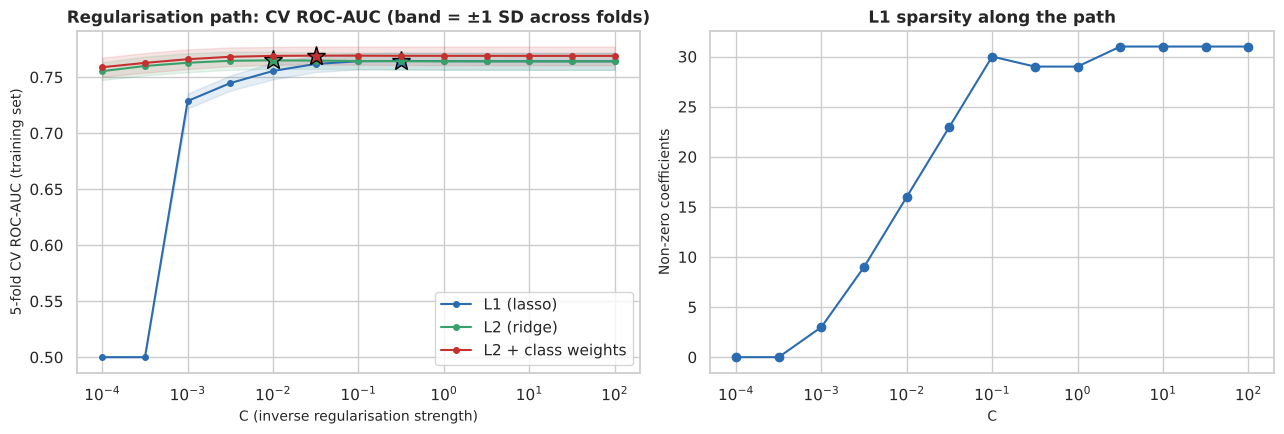

In [2]:
models = {"baseline": make_pipeline("baseline").fit(X_tr, y_tr)}
grids = {}
for kind in ("l1", "l2", "weighted"):
    grids[kind] = tune(kind, X_tr, y_tr, scoring="roc_auc")
    models[kind] = grids[kind].best_estimator_
best = pd.DataFrame({k: {"best_C": g.best_params_["clf__C"], "cv_roc_auc_mean": g.best_score_,
                         "cv_roc_auc_std": g.cv_results_["std_test_score"][g.best_index_]} for k, g in grids.items()}).T
display(best.round(4))

# L1 sparsity along the path (training data only)
l1_nonzero = [int((make_pipeline("l1", C=c).fit(X_tr, y_tr).named_steps["clf"].coef_ != 0).sum()) for c in C_GRID]
viz.plot_cv_curves(grids, C_GRID, l1_nonzero)
print("L1 non-zero coefficients along C grid:", l1_nonzero)

**Interpretation.** Discrimination is almost insensitive to regularisation strength. For L2, CV ROC-AUC is 0.7641 at the weakest penalty (C ≥ 3) and peaks at only 0.7650 (C = 0.01), a gain of about 0.001 that is far below the fold standard deviation (≈ 0.0076). The same holds for the class-weighted model (0.7690 → 0.7692). Strong penalties do hurt: at C = 10⁻⁴ L2 falls to 0.755 and L1 collapses to 0.500 because it removes every feature (the sparsity panel shows 0, 0, then 3 features at C = 10⁻³). With 18,000 training rows and 31 features there is little overfitting for the penalty to remove, so regularisation matters here for **coefficient stability and sparsity**, not for ranking power. L1 retains 29 of 31 features at its optimum, so it works as a mild selector rather than a strong one.

## 2. Training versus validation performance (threshold 0.5)

In [3]:
train_tab = metrics_table(models, X_tr, y_tr)
val_tab = metrics_table(models, X_va, y_va)
cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier", "ks"]
print("TRAINING"); display(train_tab[cols].astype(float).round(4))
print("VALIDATION"); display(val_tab[cols].astype(float).round(4))
print("Validation confusion counts"); display(val_tab[["tn", "fp", "fn", "tp"]])
print("Majority-class accuracy on validation:", round(1 - y_va.mean(), 4))

TRAINING


,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,ks
baseline,0.8125,0.6592,0.3157,0.4269,0.7675,0.5214,0.1386,0.4209
l1,0.8122,0.6582,0.3139,0.4251,0.7674,0.5212,0.1386,0.4222
l2,0.8113,0.6589,0.3046,0.4166,0.7677,0.5195,0.1389,0.4211
weighted,0.7486,0.4519,0.6411,0.5302,0.7723,0.5151,0.1882,0.4207


VALIDATION


,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,ks
baseline,0.8067,0.6323,0.3007,0.4076,0.7478,0.4937,0.1435,0.3813
l1,0.8057,0.6292,0.2954,0.4021,0.7482,0.4938,0.1434,0.3813
l2,0.8043,0.6277,0.2833,0.3904,0.7501,0.4926,0.1434,0.3850
weighted,0.7433,0.4414,0.6044,0.5102,0.7552,0.4904,0.1915,0.3876


Validation confusion counts


,tn,fp,fn,tp
baseline,4441.0,232.0,928.0,399.0
l1,4442.0,231.0,935.0,392.0
l2,4450.0,223.0,951.0,376.0
weighted,3658.0,1015.0,525.0,802.0


Majority-class accuracy on validation: 0.7788


**Interpretation.**
- **Discrimination is similar for all four.** Validation ROC-AUC is 0.7478 (baseline), 0.7482 (L1), 0.7501 (L2) and 0.7552 (class-weighted); PR-AUC is 0.490–0.494 for all four. The differences between the first three (≤ 0.0023) are well inside the sampling noise of a 6,000-row validation set, and I have not run formal tests on these differences.
- **Little overfitting.** Training ROC-AUC is 0.7675–0.7723 against 0.748–0.755 on validation, a gap of about 0.02 for every model, which is moderate and consistent across models.
- **Accuracy hides the problem.** Predicting 'no default' for everyone gives 77.9% validation accuracy. The unweighted models reach 80.4–80.7% accuracy but catch only 28–30% of defaulters at the 0.5 threshold (recall), although precision is 63%. Accuracy rewards ignoring the minority class.
- **Class weighting changes the operating point, not the ranking power.** At threshold 0.5 it raises recall to 60.4% but cuts precision to 44.1% (1,015 false positives versus about 225), and its Brier score worsens from about 0.143 to 0.192, showing that its probabilities are inflated relative to observed default frequencies. Its higher ROC-AUC (+0.005 to +0.007) is consistent with its higher CV score, but is a small effect and not enough to override the calibration concern for a PD model.
- Threshold-based metrics here use 0.5 only to compare models on equal footing; choosing a threshold is analysed in notebook 04.

'results/figures/16_confusion_matrices_validation.png'

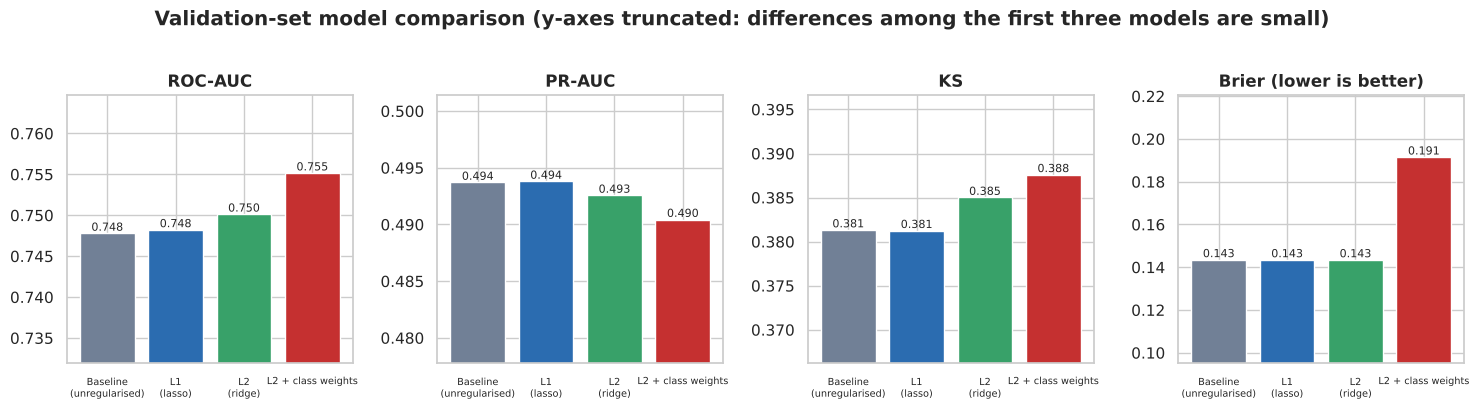

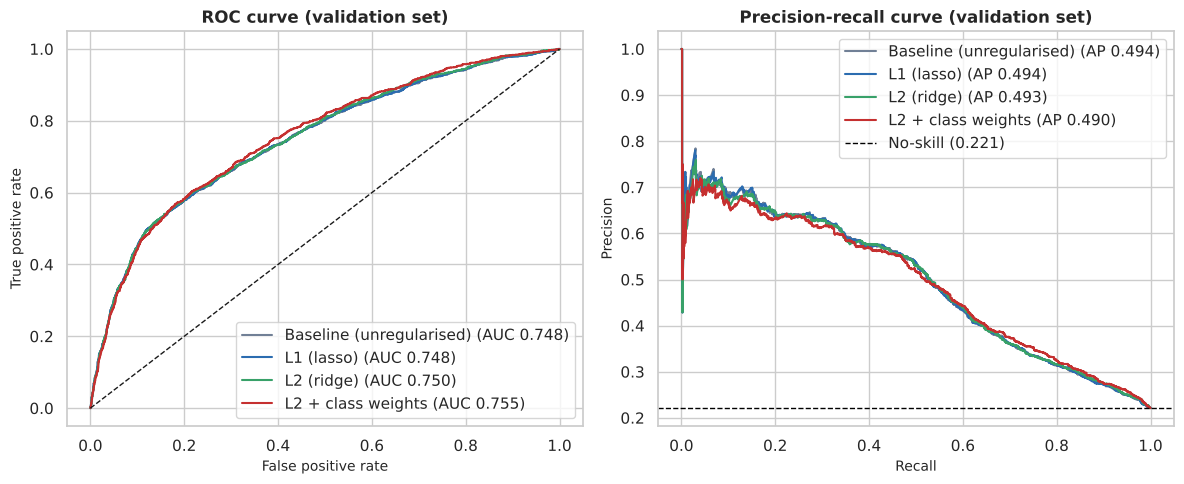

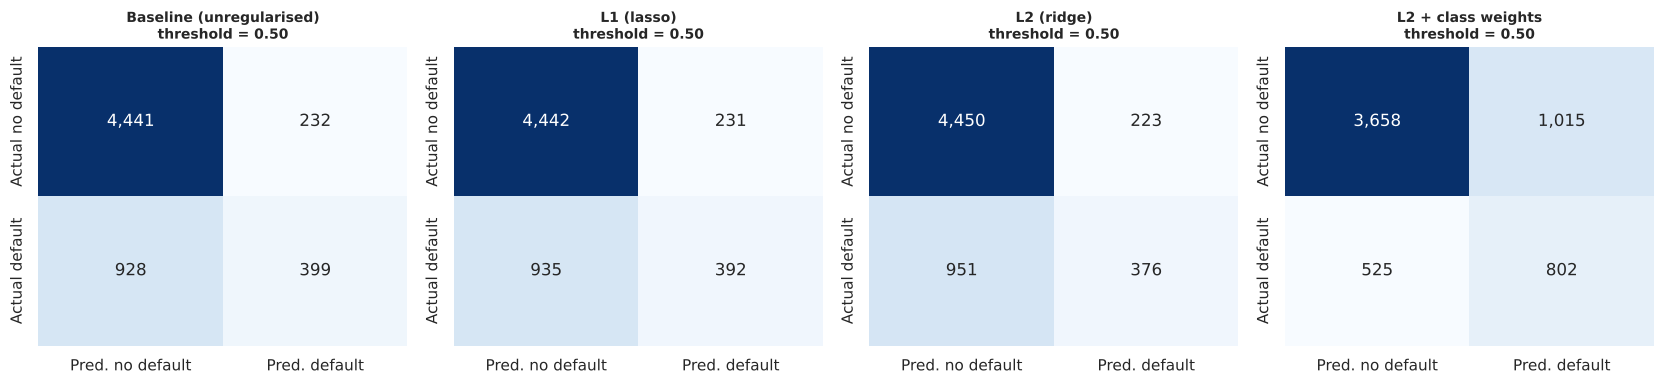

In [4]:
viz.plot_model_comparison(val_tab)
viz.plot_roc_pr(models, X_va, y_va)
viz.plot_confusion_matrices(models, X_va, y_va)

## 3. What regularisation does to the coefficients

,baseline,l1,l2,weighted
EDUCATION_4,-1.255,-1.066,-0.213,-0.594
n_late_months,0.550,0.545,0.476,0.436
max_delay,0.302,0.304,0.299,0.331
PAY_0,0.327,0.322,0.312,0.278
PAY_2,-0.137,-0.126,-0.077,-0.044
PAY_4,-0.115,-0.111,-0.079,-0.069
pay_ratio_avg,0.098,0.087,0.095,0.213
BILL_AMT1,0.133,0.123,0.092,0.096


L1 non-zero coefficients at the tuned C: 29 of 31
Features zeroed by L1: ['EDUCATION_2', 'MARRIAGE_3']
Sum |coef|:  {'baseline': 4.48, 'l1': 4.12, 'l2': 2.95, 'weighted': 3.68}


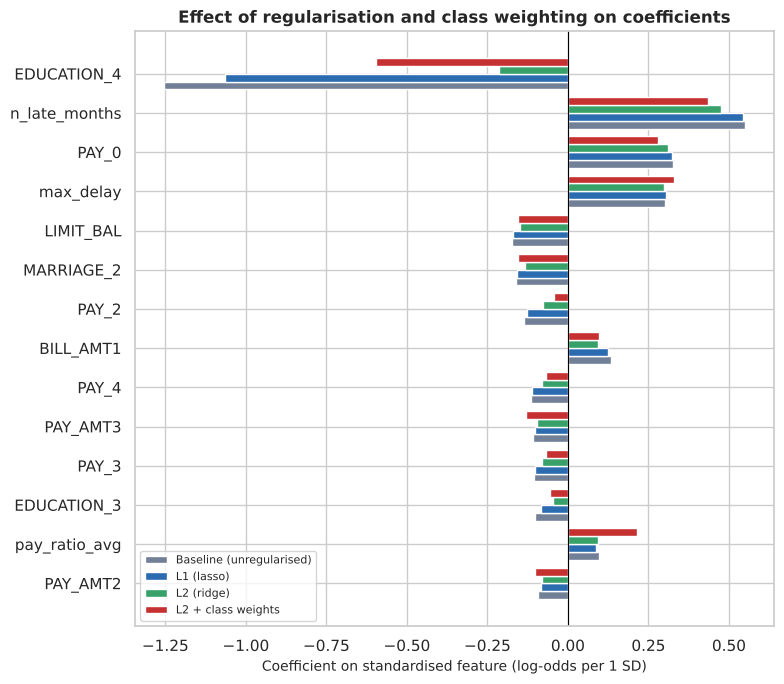

In [5]:
coefs = pd.concat({k: coefficient_table(m)["coef"] for k, m in models.items()}, axis=1)
viz.plot_coef_comparison(coefs)
display(coefs.loc[["EDUCATION_4", "n_late_months", "max_delay", "PAY_0", "PAY_2", "PAY_4", "pay_ratio_avg", "BILL_AMT1"]].round(3))
print("L1 non-zero coefficients at the tuned C:", int((models["l1"].named_steps["clf"].coef_ != 0).sum()), "of", coefs.shape[0])
print("Features zeroed by L1:", list(coefs.index[coefs["l1"] == 0]))
print("Sum |coef|: ", coefs.abs().sum().round(2).to_dict())

**Interpretation.**
- **Regularisation shrinks coefficients most where the data are thin or collinear.** The sum of absolute coefficients falls from 4.48 (baseline) to 4.12 (L1) and 2.95 (L2). The clearest case is the small 'others' education group (468 rows): its coefficient is -1.26 unregularised and -0.21 under L2, i.e. L2 refuses to trust an extreme estimate from a tiny group.
- **Dominant risk drivers are stable across models.** `n_late_months` (0.48–0.55), `max_delay` (≈ 0.30) and `PAY_0` (0.28–0.33) keep the same sign and similar size in all four models.
- **Individual delay coefficients are not directly interpretable.** `PAY_2` to `PAY_6` have negative coefficients even though delinquency raises default risk in the raw data. These variables are strongly correlated with `PAY_0`, `max_delay` and `n_late_months`, so their coefficients adjust for those instead of measuring a standalone effect. Notebook 04 treats the coefficients with this caveat and uses statsmodels significance tests and odds ratios.
- L1 sets only two coefficients to exactly zero (`EDUCATION_2`, `MARRIAGE_3`).
- Class weighting changes several coefficients (e.g. `pay_ratio_avg` 0.095 → 0.213), a reminder that it refits a different loss and does not merely move the threshold.

## 4. Model selection and saved results

In [6]:
eligible = val_tab.loc[["baseline", "l1", "l2"], "roc_auc"].astype(float)
top = eligible.max()
close = eligible[eligible >= top - 0.002].index.tolist()
selected = "l2" if "l2" in close else eligible.idxmax()
print("validation ROC-AUC of eligible models:", eligible.round(4).to_dict())
print("within 0.002 of best:", close, "-> selected PD model:", selected)

# Save artefacts (training and validation only; test results are produced once in notebook 04)
comp = pd.concat([best, val_tab[["roc_auc", "pr_auc", "brier", "ks"]].astype(float).add_prefix("val_"),
                  train_tab[["roc_auc"]].astype(float).add_prefix("train_")], axis=1)
comp.round(5).to_csv(f"{RESULTS}/model_comparison.csv", index_label="model")
long = pd.concat([train_tab.assign(split="train"), val_tab.assign(split="validation")]).reset_index(names="model")
long = long[["model", "split"] + [c for c in long.columns if c not in ("model", "split")]]
long.round(5).to_csv(f"{RESULTS}/model_metrics.csv", index=False)
for k, m in models.items():
    joblib.dump(m, f"{MODELS}/logreg_{k}.joblib")
(pd.Series({"selected_pd_model": selected, "seed": SEED})).to_json(f"{MODELS}/selection.json")
print("saved:", sorted(p for p in __import__('os').listdir(MODELS)))

validation ROC-AUC of eligible models: {'baseline': 0.7478, 'l1': 0.7482, 'l2': 0.7501}
within 0.002 of best: ['l1', 'l2'] -> selected PD model: l2


saved: ['logreg_baseline.joblib', 'logreg_l1.joblib', 'logreg_l2.joblib', 'logreg_weighted.joblib', 'selection.json']


**Result.** The baseline, L1 and L2 models are within 0.002 ROC-AUC of each other (L1 and L2 are within 0.002 of the best, and L2 is the best), so the pre-declared rule selects **L2 (C = 0.01)** as the PD model. It also has the best validation KS among the eligible models (0.385) and an equal Brier score (0.143).

**Honest caveats.**
- The class-weighted model has the highest validation ROC-AUC (0.7552) but was excluded by the pre-declared rule on calibration grounds. A recalibrated weighted model would be a legitimate alternative, and notebook 04 does not claim L2 dominates it on ranking.
- Selecting among close candidates on a single validation set carries some selection noise. The test set remains untouched and is evaluated once, in notebook 04, for the selected model only.
- Models are saved in `models/` (about a few kB each); the selection is stored in `models/selection.json`.